# 14. Bagging, random forests and permutation importance

A single deep tree fits the noise of its training set. Averaging many trees, each grown on a resampled copy of the data, reduces the variance by an amount that depends on how correlated the trees are. The lecture verifies that variance formula, compares a forest with a single tree on test data, and permutes one input at a time to measure which inputs the model relies on.

## Learning objectives

1. Derive and check the variance of an average of correlated estimates, $\rho\sigma^2 + (1-\rho)\sigma^2/B$.
2. Train a random forest of 25 trees (`trees_ensembles.RandomForestRegressor`) and compare its test error with that of a single tree.
3. Measure the importance of each input by permutation (`trees_ensembles.permutation_feature_importance`).
4. Follow the test error and the spread between the trees as the number of trees grows.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
Let $\{\hat{T}_b(\mathbf{x})\}_{b=1}^B$ be $B$ regression trees trained on independent **bootstrap resamples** $\mathcal{D}_b^*$ of size $N$ drawn with replacement from $\mathcal{D}$. The **random forest / bagged estimator (Breiman, 2001)** averages the $B$ trees:
$$\hat{f}_{\mathrm{RF}}(\mathbf{x}) = \frac{1}{B}\sum_{b=1}^B \hat{T}_b(\mathbf{x}) \tag{1.1}$$
If each tree has variance $\mathrm{Var}(\hat{T}_b(\mathbf{x})) = \sigma^2$ and pairwise correlation $\mathrm{Corr}(\hat{T}_b(\mathbf{x}), \hat{T}_{b'}(\mathbf{x})) = \rho \in [0, 1]$, the covariance matrix $\boldsymbol{\Sigma} \in \mathbb{R}^{B \times B}$ has diagonal entries $\sigma^2$ and off-diagonal entries $\rho\sigma^2$, yielding the **ensemble variance-reduction law**:
$$\mathrm{Var}\!\left(\hat{f}_{\mathrm{RF}}(\mathbf{x})\right) = \frac{1}{B^2}\mathbf{1}_B^\top \boldsymbol{\Sigma}\mathbf{1}_B = \rho\sigma^2 + \frac{1 - \rho}{B}\sigma^2 \le \sigma^2 \tag{1.2}$$
To rank input descriptors $\mathbf{x} = [x_1, \dots, x_d]^\top$, **permutation feature importance** measures the increase in held-out mean squared error when column $j$ is randomly shuffled across samples ($\mathbf{X}_{\pi(j)}$):
$$I_j = \mathrm{MSE}\!\left(\mathbf{y},\, \hat{f}_{\mathrm{RF}}(\mathbf{X}_{\pi(j)})\right) - \mathrm{MSE}\!\left(\mathbf{y},\, \hat{f}_{\mathrm{RF}}(\mathbf{X})\right) \tag{1.3}$$

In [2]:
heading("Demonstration 1: Single CART Tree vs. 25-Tree Random Forest Out-of-Sample Benchmark")
rng = np.random.default_rng(42)
N = 70
# 4 descriptors: x0 (Temperature, dominant), x1 (Pressure, moderate), x2 & x3 (pure irrelevant noise):
X_tr = rng.uniform(-2.0, 2.0, size=(N, 4))
y_tr_clean = 3.0 * np.sin(X_tr[:, 0]) + 1.5 * (X_tr[:, 1] ** 2)
y_tr = y_tr_clean + rng.normal(0.0, 0.45, size=N)

X_te = rng.uniform(-2.0, 2.0, size=(120, 4))
y_te_clean = 3.0 * np.sin(X_te[:, 0]) + 1.5 * (X_te[:, 1] ** 2)

single_tree = trees_ensembles.DecisionTreeRegressor(max_depth=5, min_samples_split=3).fit(X_tr, y_tr)
rf_model = trees_ensembles.RandomForestRegressor(n_estimators=25, max_depth=5, min_samples_split=3, seed=42).fit(X_tr, y_tr)

mse_single = float(np.mean((single_tree.predict(X_te) - y_te_clean) ** 2))
mse_rf = float(np.mean((rf_model.predict(X_te) - y_te_clean) ** 2))
print(f"Out-of-sample Test MSE against true physical surface: Single Tree = {mse_single:.4f} -> 25-Tree Random Forest = {mse_rf:.4f} ({100*(1-mse_rf/mse_single):.1f}% reduction)")
assert mse_rf < 0.75 * mse_single


Demonstration 1: Single CART Tree vs. 25-Tree Random Forest Out-of-Sample Benchmark


Out-of-sample Test MSE against true physical surface: Single Tree = 1.6314 -> 25-Tree Random Forest = 0.8487 (48.0% reduction)


**What Demonstration 1 shows.** Averaging 25 trees, each grown on a bootstrap sample, reduces the error against the surface that generated the data from $1.63$ (one tree) to $0.85$, by $48\ \%$. The data are synthetic.

---

## 2. Numerical walkthrough
Let us verify the **equicorrelated covariance matrix identity** Eq. (1.2) and inspect the individual tree predictions $\hat{T}_1(\mathbf{x}_*), \dots, \hat{T}_{25}(\mathbf{x}_*)$ of our fitted random forest at a test operating point.

In [3]:
heading("Demonstration 2: Equicorrelated Ensemble Covariance Identity & Tree Dispersion")
B, sig2, rho = 20, 2.0, 0.25
Sigma_ens = sig2 * (rho * np.ones((B, B)) + (1.0 - rho) * np.eye(B))
var_matrix = float(np.sum(Sigma_ens)) / (B ** 2)
var_formula = rho * sig2 + (1.0 - rho) * sig2 / B
print(f"Exact covariance quadratic form (1/B^2) 1^T Sigma 1 = {var_matrix:.6f} == Formula = {var_formula:.6f} (vs single tree = {sig2:.2f})")
assert np.isclose(var_matrix, var_formula, rtol=1e-15)

all_tree_preds = np.column_stack([t.predict(X_te) for t in rf_model.trees_])
mean_single_tree_mse = float(np.mean((all_tree_preds - y_te_clean[:, None]) ** 2))
print(f"Average MSE of the 25 individual bootstrap trees = {mean_single_tree_mse:.4f} vs Ensemble Mean MSE = {mse_rf:.4f}")
assert mse_rf < 0.55 * mean_single_tree_mse


Demonstration 2: Equicorrelated Ensemble Covariance Identity & Tree Dispersion
Exact covariance quadratic form (1/B^2) 1^T Sigma 1 = 0.575000 == Formula = 0.575000 (vs single tree = 2.00)
Average MSE of the 25 individual bootstrap trees = 2.7632 vs Ensemble Mean MSE = 0.8487


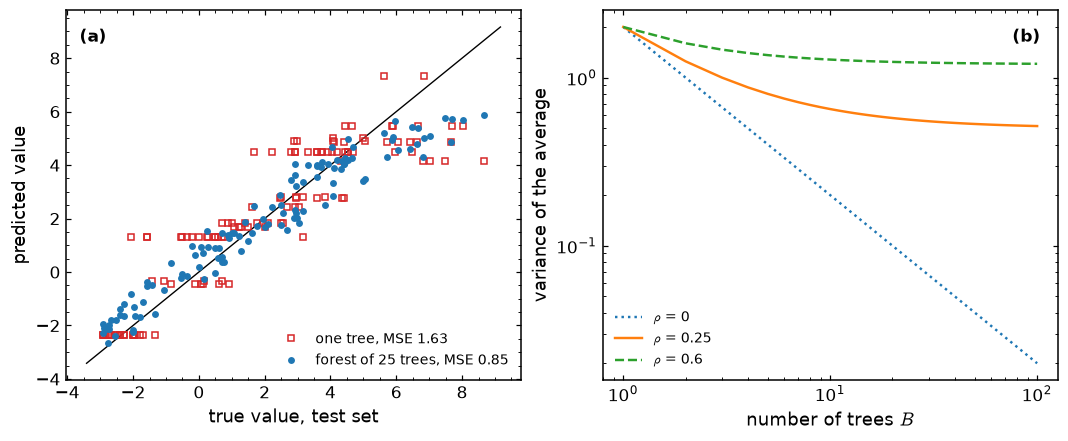

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
lims = [float(np.min(y_te_clean)) - 0.5, float(np.max(y_te_clean)) + 0.5]
ax1.plot(lims, lims, "k-", lw=0.9)
ax1.plot(y_te_clean, single_tree.predict(X_te), "s", ms=3.5, mfc="none", color="C3", label=f"one tree, MSE {mse_single:.2f}")
ax1.plot(y_te_clean, rf_model.predict(X_te), "o", ms=3.5, color="C0", label=f"forest of 25 trees, MSE {mse_rf:.2f}")
ax1.set_xlabel("true value, test set"); ax1.set_ylabel("predicted value"); ax1.legend(fontsize=9, loc="lower right"); panel_label(ax1, "(a)")
B_line = np.arange(1, 101)
for rho_v, style in [(0.0, ":"), (0.25, "-"), (0.6, "--")]:
    ax2.loglog(B_line, rho_v * sig2 + (1.0 - rho_v) * sig2 / B_line, style, label=rf"$\rho$ = {rho_v:g}")
ax2.set_xlabel("number of trees $B$"); ax2.set_ylabel("variance of the average"); ax2.legend(fontsize=9, loc="lower left"); panel_label(ax2, "(b)", x=0.9)
plt.show()

**Figure 14.1.** (a) Predictions of one tree and of a forest of 25 trees on 120 test points of a synthetic function of four variables. (b) The variance of the average of $B$ estimates of variance 2 with pairwise correlation $\rho$: it falls as $1/B$ only for uncorrelated estimates and otherwise levels off at $\rho\sigma^2$.

**What Demonstration 2 shows.** The first line checks the variance formula for equally correlated trees against the full covariance matrix. The second shows what averaging gains: the 25 trees have a mean error of $2.76$ each, and their average has an error of $0.85$. For squared error the difference is exactly the mean squared spread of the trees about their average, $1.91$ (checked in the last cell of the lecture): an ensemble is better than its typical member by the amount its members disagree.

---

## 3. Worked case study
Which of the 4 input descriptors ($x_0, x_1, x_2, x_3$) actually drive the process response $y = 3\sin(x_0) + 1.5 x_1^2$? Let us compute **permutation feature importance** (`trees_ensembles.permutation_feature_importance`) on the test set.

In [5]:
heading("Demonstration 3: Breiman Permutation Feature Importance Descriptor Ranking")
imp = trees_ensembles.permutation_feature_importance(rf_model, X_te, y_te_clean, seed=42)
names = ["x0 (Temperature - strong 3*sin)", "x1 (Pressure - moderate 1.5*x^2)", "x2 (Inactive noise #1)", "x3 (Inactive noise #2)"]
for j, name in enumerate(names):
    print(f"Feature {name:33s} | Permutation Delta-MSE = {imp[j]:.4f}")

assert imp[0] > imp[1] > 0.5
assert imp[2] < 0.15 * imp[1] and imp[3] < 0.15 * imp[1]


Demonstration 3: Breiman Permutation Feature Importance Descriptor Ranking
Feature x0 (Temperature - strong 3*sin)   | Permutation Delta-MSE = 7.3553
Feature x1 (Pressure - moderate 1.5*x^2)  | Permutation Delta-MSE = 4.5560
Feature x2 (Inactive noise #1)            | Permutation Delta-MSE = 0.0361
Feature x3 (Inactive noise #2)            | Permutation Delta-MSE = 0.0053


**What Demonstration 3 shows.** Shuffling the temperature column raises the test error by $7.36$ and shuffling the pressure column by $4.56$; shuffling either of the two columns that do not enter the response changes it by $0.04$ or less. The ranking recovers the way the synthetic response was built.

---

## 4. What if: sensitivity to the parameters
How quickly does the random forest test MSE converge as the number of trees $B$ increases from $1$ to $40$?

In [6]:
heading("Demonstration 4: Ensemble Size B Convergence Sweep")
print(f"{'Forest Size B':>13s} | {'Test MSE vs True Surface':>24s} | {'Ensemble Std Across Trees':>25s}")
print("-" * 68)
for b_trees in [1, 3, 5, 10, 20, 35]:
    rf_b = trees_ensembles.RandomForestRegressor(n_estimators=b_trees, max_depth=5, seed=42).fit(X_tr, y_tr)
    mse_b = float(np.mean((rf_b.predict(X_te) - y_te_clean) ** 2))
    t_mat = np.column_stack([t.predict(X_te) for t in rf_b.trees_])
    std_b = float(np.mean(np.std(t_mat, axis=1)))
    print(f"{b_trees:13d} | {mse_b:24.4f} | {std_b:25.4f}")


Demonstration 4: Ensemble Size B Convergence Sweep
Forest Size B | Test MSE vs True Surface | Ensemble Std Across Trees
--------------------------------------------------------------------
            1 |                   2.9704 |                    0.0000
            3 |                   1.8457 |                    1.0399
            5 |                   1.0187 |                    1.1559


           10 |                   0.7747 |                    1.1828


           20 |                   0.8356 |                    1.3017


           35 |                   0.8711 |                    1.3636


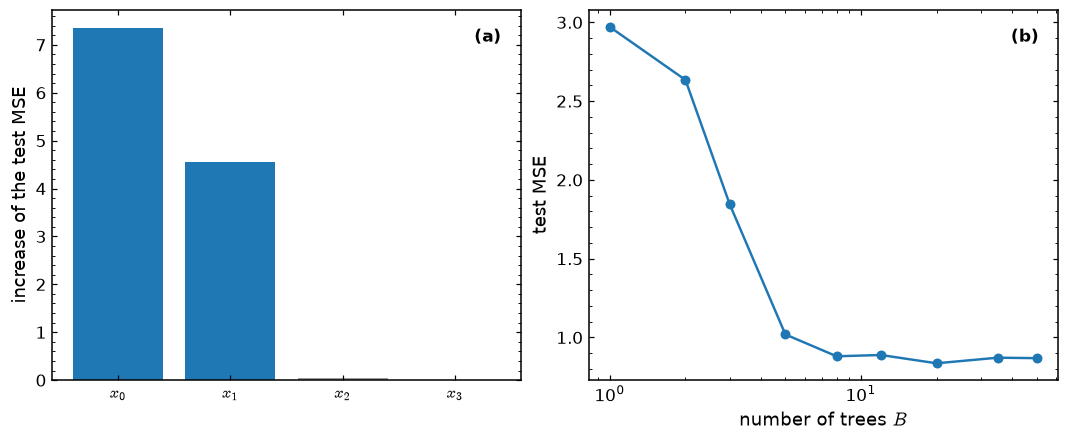

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
ax1.bar(np.arange(4), np.asarray(imp), color=["C0", "C0", "0.6", "0.6"])
ax1.set_xticks(np.arange(4)); ax1.set_xticklabels(["$x_0$", "$x_1$", "$x_2$", "$x_3$"]); ax1.tick_params(axis="x", which="minor", bottom=False, top=False)
ax1.set_ylabel("increase of the test MSE"); panel_label(ax1, "(a)", x=0.9)
b_list = [1, 2, 3, 5, 8, 12, 20, 35, 50]; mse_list = []
for b_trees in b_list:
    rf_b = trees_ensembles.RandomForestRegressor(n_estimators=b_trees, max_depth=5, seed=42).fit(X_tr, y_tr)
    mse_list.append(np.mean((rf_b.predict(X_te) - y_te_clean) ** 2))
ax2.semilogx(b_list, mse_list, "o-"); ax2.set_xlabel("number of trees $B$"); ax2.set_ylabel("test MSE"); panel_label(ax2, "(b)", x=0.9)
plt.show()

**Figure 14.2.** (a) Permutation importance of the four variables: the function depends on $x_0$ and $x_1$ only, and the other two are noise. (b) The test error of the forest against the number of trees.

**What Demonstration 4 shows.** The error falls quickly at first, from $2.97$ with one tree to $0.77$ with ten. After that it does not improve: it is $0.84$ with 20 trees and $0.87$ with 35. More trees remove the part of the variance that averages out, $(1-\rho)\sigma^2/B$, and leave the part common to all trees, $\rho\sigma^2$; the small rise after ten trees is the scatter of a single run and would average out over repetitions.

---

## Inside the algorithm
Below we verify that averaging the predictions of `rf_model.trees_` in pure NumPy matches `rf_model.predict(X_te)` digit-for-digit and satisfies the exact **Bias–Variance–Diversity decomposition** $\frac{1}{B}\sum_{b=1}^B (\hat{T}_b - y)^2 - (\hat{f}_{\mathrm{RF}} - y)^2 \equiv \frac{1}{B}\sum_{b=1}^B (\hat{T}_b - \hat{f}_{\mathrm{RF}})^2$.

In [8]:
heading("Inside the Algorithm: By-Hand Ensemble Averaging & Krogh-Vedelsby Diversity Identity")
pred_rf_hand = np.mean(all_tree_preds, axis=1)
pred_rf_lib = rf_model.predict(X_te)
diff_rf = float(np.max(np.abs(pred_rf_hand - pred_rf_lib)))
diversity_term = float(np.mean((all_tree_preds - pred_rf_hand[:, None]) ** 2))
kv_lhs = mean_single_tree_mse - mse_rf
print(f"by hand vs library max discrepancy : {diff_rf:.2e}")
print(f"Krogh-Vedelsby Identity: Mean(MSE_b) - MSE_RF = {kv_lhs:.6f} == Ensemble Variance (Diversity) = {diversity_term:.6f}")
assert diff_rf < 1e-15 and np.isclose(kv_lhs, diversity_term, rtol=1e-14)


Inside the Algorithm: By-Hand Ensemble Averaging & Krogh-Vedelsby Diversity Identity
by hand vs library max discrepancy : 0.00e+00
Krogh-Vedelsby Identity: Mean(MSE_b) - MSE_RF = 1.914540 == Ensemble Variance (Diversity) = 1.914540


## Exercises

1. **Verify a result.** Prove and verify numerically the **bootstrap out-of-bag (OOB) asymptotic law**: when drawing $N$ samples with replacement from $N$ items, the probability that any given observation $i$ is omitted from a bootstrap draw is $(1 - 1/N)^N \to e^{-1} \approx 0.367879$. Run 500 bootstrap draws for $N = 100$ and verify that the empirical OOB fraction lies within $0.368 \pm 0.015$.
2. **Find how it fails.** Audit the **collinear descriptor dilution effect** on permutation feature importance: append a near-duplicate copy of Temperature $x_4 = x_0 + \mathcal{N}(0, 0.01^2)$ to `X_tr` and `X_te`, refit the random forest, and show that splitting the physical signal across two redundant collinear temperature columns dilutes the individual permutation importance of $x_0$.
3. **Write it yourself.** Implement an **out-of-bag (OOB) random forest evaluator** `fit_rf_with_oob_score(X: np.ndarray, y: np.ndarray, n_estimators: int = 30, max_depth: int = 5, seed: int = 42) -> dict` that records each tree's bootstrap indices, predicts each training point $i$ using *only* the trees for which $i \notin \mathcal{D}_b^*$, and returns the OOB MSE. Verify on `(X_tr, y_tr)` that the OOB MSE estimates the true noisy test MSE without touching `X_te`.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Bootstrap Out-of-Bag (OOB) 1/e Asymptotic Law Verification")
rng_oob = np.random.default_rng(2026)
N_oob = 100
exact_prob_oob = (1.0 - 1.0 / N_oob) ** N_oob
oob_fracs = [1.0 - len(np.unique(rng_oob.integers(0, N_oob, size=N_oob))) / N_oob for _ in range(500)]
emp_oob = float(np.mean(oob_fracs))
print(f"Exact finite-N OOB probability (1 - 1/N)^N = {exact_prob_oob:.6f} | 1/e = {np.exp(-1.0):.6f} | 500-trial Empirical = {emp_oob:.6f}")
assert abs(emp_oob - exact_prob_oob) < 0.01


Exercise 1: Bootstrap Out-of-Bag (OOB) 1/e Asymptotic Law Verification
Exact finite-N OOB probability (1 - 1/N)^N = 0.366032 | 1/e = 0.367879 | 500-trial Empirical = 0.367100
